# Mock Lab 1 — Premium Card Targeting (Classification + Imbalanced)
**เวลา:** 90 นาที (Python) + 60 นาที (สร้างซ้ำส่วน C ใน RapidMiner) · **seed = 1992** · **5-fold stratified CV** ทุกข้อที่ประเมินโมเดล

ธนาคารต้องการเสนอ **บัตรเครดิตพรีเมียม** ให้คนที่มีรายได้ **> 50K** และอยากหา "คนรายได้สูง" ให้ได้มากที่สุด
ข้อมูลถูกส่งมา 3 ไฟล์ใน `data/`:
- `people.csv` — ข้อมูลส่วนตัว (key = `person_id`)
- `work_2025H1.csv`, `work_2025H2.csv` — ข้อมูลการทำงาน + `income` (target) แบ่งเป็นสองช่วงเวลา คอลัมน์เหมือนกัน
- `new_person.csv` — ลูกค้าใหม่ 1 คน (ไม่มี income)

> ทุกข้อให้ตอบครบ: **process/โค้ด → ตั้งค่าที่ใช้ → ผล (ตาราง/กราฟ) → การตีความ**

## ตั้งต้น

In [1]:
import warnings; warnings.filterwarnings("ignore", category=UserWarning)   # ซ่อน warning precision=0 ของ baseline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from mlxtend.frequent_patterns import apriori, association_rules
SEED = 1992

## Part A · Data Handling (20 คะแนน)

**A1.** อ่านไฟล์ทั้ง 3 ไฟล์ ต่อ `work_2025H1` กับ `work_2025H2` เป็นตารางเดียว แล้ว **join** กับ `people` ด้วย `person_id` · รายงานจำนวนแถว/คอลัมน์ก่อนและหลัง join และอธิบายว่าเลือก join แบบไหนเพราะอะไร

In [2]:
people = pd.read_csv("data/people.csv")
h1 = pd.read_csv("data/work_2025H1.csv")
h2 = pd.read_csv("data/work_2025H2.csv")
print(set(h1.columns) ^ set(h2.columns))                 # set() = คอลัมน์ตรงกัน ต่อแถวได้
work = pd.concat([h1, h2], ignore_index=True)
print("people", people.shape, "| work", work.shape)
print("key ซ้ำ:", people["person_id"].duplicated().sum(), work["person_id"].duplicated().sum())
df = pd.merge(people, work, on="person_id", how="inner", validate="one_to_one")
print("joined", df.shape)

set()
people (5999, 9) | work (5999, 8)
key ซ้ำ: 0 0
joined (5999, 16)


> **✅ เฉลย / การตีความ**
>
> work = 3,500 + 2,499 = **5,999 แถว** (คอลัมน์ตรงกันทั้งสองไฟล์) · people = 5,999 แถว · key ไม่ซ้ำทั้งสองฝั่ง
> หลัง join ได้ **5,999 × 16** (9 + 8 − key ที่ซ้ำ 1)
> เลือก **inner join** เพราะต้องการเฉพาะคนที่มีทั้งข้อมูลส่วนตัวและข้อมูลการทำงาน + target · ผลเท่ากับ left join ในกรณีนี้ (ทุก id มีคู่) · ใส่ `validate="one_to_one"` เพื่อยืนยันว่าไม่มี key ซ้ำทำให้แถวงอก

**A2.** ข้อมูลใช้ `"?"` แทนค่าว่าง จงแปลงเป็น missing, นับค่าว่างต่อคอลัมน์ และหาสัดส่วนคนรายได้ > 50K · ข้อมูลสมดุลหรือไม่

In [3]:
df = df.replace("?", np.nan)
print(df.isna().sum().loc[lambda s: s > 0])
df["rich"] = (df["income"] == ">50K").astype(int)
print(df["rich"].value_counts(normalize=True).round(4))

native-country    118
workclass         368
occupation        369
dtype: int64
rich
0    0.7606
1    0.2394
Name: proportion, dtype: float64


> **✅ เฉลย / การตีความ**
>
> ค่าว่าง: workclass **368**, occupation **369**, native-country **118** (≈ 6% / 6% / 2%)
> รายได้ > 50K = **23.9%** → **ไม่สมดุล** (IR ≈ 76.1/23.9 = 3.2 : 1) → ห้ามดู accuracy อย่างเดียว · baseline ทาย "≤ 50K" ทุกคนก็ได้ accuracy ~76%

**A3.** ทำ **pivot table** สัดส่วนคนรายได้ > 50K โดยแถว = `education` คอลัมน์ = `gender` (เรียงตาม Male มากไปน้อย แสดง 5 แถวแรก) และตีความ 1–2 ประโยค

In [4]:
pv = pd.pivot_table(df, index="education", columns="gender", values="rich", aggfunc="mean").round(3)
pv.sort_values("Male", ascending=False).head(5)

gender,Female,Male
education,,
Prof-school,0.286,0.816
Doctorate,0.692,0.762
Masters,0.329,0.649
Bachelors,0.213,0.477
Assoc-acdm,0.130,0.333


> **✅ เฉลย / การตีความ**
>
> Prof-school (Male 81.6%), Doctorate (76.2%), Masters (64.9%) มีสัดส่วนรายได้สูงมากที่สุด → **การศึกษาสูงสัมพันธ์กับรายได้สูง**
> และในทุกระดับการศึกษา **ชายมีสัดส่วนรายได้สูงกว่าหญิง** (เช่น Prof-school 81.6% vs 28.6%) · ⚠️ เป็นความสัมพันธ์ ไม่ใช่เหตุ-ผล และบางกลุ่ม (หญิง Prof-school) มีจำนวนน้อย ค่าจึงแกว่งได้

**A4.** วาดกราฟ 2 รูปที่เหมาะสม: (1) การกระจายของ `age` แยกตามกลุ่มรายได้ (2) สัดส่วนรายได้ > 50K ตาม `occupation` · ตีความแต่ละรูป

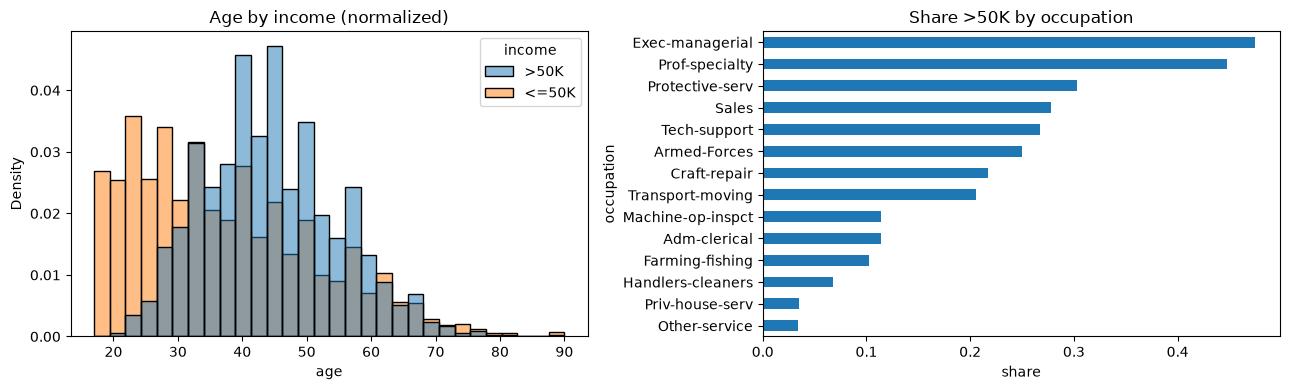

occupation
Protective-serv    0.303
Prof-specialty     0.448
Exec-managerial    0.475
Name: rich, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df, x="age", hue="income", stat="density", common_norm=False, bins=30, ax=ax[0])
ax[0].set_title("Age by income (normalized)")
occ = df.groupby("occupation")["rich"].mean().sort_values()
occ.plot.barh(ax=ax[1]); ax[1].set_title("Share >50K by occupation"); ax[1].set_xlabel("share")
plt.tight_layout(); plt.show()
print(occ.tail(3).round(3))

> **✅ เฉลย / การตีความ**
>
> (1) histogram แบบ normalize (เพราะสองกลุ่มขนาดต่างกัน): กลุ่ม > 50K กระจุกช่วง **~35–55 ปี** ส่วนกลุ่ม ≤ 50K มีคนอายุน้อย (< 30) จำนวนมาก → อายุ/ประสบการณ์สัมพันธ์กับรายได้
> (2) bar แนวนอนเรียงค่า: Exec-managerial และ Prof-specialty มีสัดส่วนรายได้สูงที่สุด ส่วนงานบริการ/แรงงานต่ำสุด → occupation เป็น feature ที่น่าจะช่วยทำนาย

## Part B · Preprocessing (20 คะแนน)

**B1.** ควรตัดคอลัมน์ใดออกก่อนสร้างโมเดล เพราะอะไร (พิจารณา `person_id`, `fnlwgt`, `educational-num`, `income`)

In [6]:
# educational-num ซ้ำกับ education หรือไม่?
print(df.groupby("education")["educational-num"].nunique().max())     # 1 → education แต่ละค่ามี educational-num ค่าเดียว
X = df.drop(columns=["person_id", "fnlwgt", "educational-num", "income", "rich"])
y = df["rich"]
print(X.shape)

1
(5999, 12)


> **✅ เฉลย / การตีความ**
>
> - **person_id** — ตัวระบุ ไม่มีความหมาย (RapidMiner: ตั้ง role = id)
> - **fnlwgt** — น้ำหนักการสุ่มของสำมะโน ไม่ใช่คุณสมบัติของบุคคล
> - **educational-num** — **redundant** กับ education (หนึ่งค่า education ↔ หนึ่งค่าตัวเลข)
> - **income / rich** — คือ target (ถ้าใส่ = leakage)
> เหลือ **12 feature** (4 ตัวเลข + 8 categorical)

**B2.** สร้าง preprocessing ที่ **ไม่ทำให้เกิด data leakage** สำหรับ: เติมค่าว่าง, scale ตัวเลข, one-hot categorical · อธิบายว่าทำไมไม่ leak

In [7]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(num_cols, cat_cols, sep="\n")

['age', 'hours-per-week', 'capital-gain', 'capital-loss']
['gender', 'race', 'native-country', 'education', 'marital-status', 'relationship', 'workclass', 'occupation']


> **✅ เฉลย / การตีความ**
>
> - ตัวเลข: **median** (capital-gain/loss เบ้มาก) + StandardScaler · categorical: **mode** + one-hot (`handle_unknown="ignore"` กัน fold ที่เจอหมวดใหม่)
> - **ไม่ leak** เพราะทุกขั้นอยู่ใน `ColumnTransformer` ที่จะถูกใส่ใน Pipeline → ตอน `cross_validate` แต่ละ fold จะ **fit imputer/scaler/encoder จาก training fold เท่านั้น** แล้วแค่ transform validation fold
> - ⚠️ ถ้า `df.fillna(df.median())` หรือ scale ทั้งตารางก่อน CV = ใช้ค่าที่รวม validation fold ไปแล้ว = leakage

**B3.** แบ่ง `age` เป็น 4 กลุ่มแบบ **equal frequency** แล้วหาสัดส่วนรายได้ > 50K ในแต่ละกลุ่ม · ทำไมเลือก equal frequency แทน equal width

In [8]:
df["age_group"] = pd.qcut(df["age"], q=4)
df.groupby("age_group", observed=True)["rich"].agg(share="mean", n="size").round(3)

,share,n
age_group,,
"(16.999, 28.0]",0.040,1576
"(28.0, 38.0]",0.245,1541
"(38.0, 48.0]",0.374,1399
"(48.0, 90.0]",0.319,1483


> **✅ เฉลย / การตีความ**
>
> | age_group | ≤ 28 | 29–38 | 39–48 | 49–90 |
> |---|---|---|---|---|
> | share > 50K | 4.0% | 24.5% | **37.4%** | 31.9% |
> สัดส่วนรายได้สูงเพิ่มตามอายุจนสูงสุดช่วง 39–48 แล้วลดลงเล็กน้อย (ใกล้เกษียณ) → ความสัมพันธ์ **ไม่เป็นเชิงเส้น**
> **equal frequency** ให้ทุกกลุ่มมีราว 1,400–1,600 คน (เทียบสัดส่วนได้น่าเชื่อถือ) · age เบ้ขวา ถ้าใช้ equal width ช่วงอายุมาก (70–90) จะมีคนน้อยมาก

## Part C · Baseline & Models (30 คะแนน)

**C1.** ประเมินด้วย 5-fold stratified CV (seed 1992): **majority baseline**, KNN (k=5), Logistic Regression, Decision Tree (max_depth=5), Random Forest (100 ต้น) · รายงาน accuracy / precision / recall / F1 ในตารางเดียว

In [9]:
def evaluate(name, clf, smote=False):
    steps = [("prep", prep)] + ([("smote", SMOTE(random_state=SEED))] if smote else []) + [("clf", clf)]
    r = cross_validate(ImbPipeline(steps), X, y, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
    return {"model": name, **{m: round(r[f"test_{m}"].mean(), 4) for m in ["accuracy", "precision", "recall", "f1"]}}

results = pd.DataFrame([
    evaluate("Majority baseline", DummyClassifier(strategy="most_frequent")),
    evaluate("KNN k=5", KNeighborsClassifier(n_neighbors=5)),
    evaluate("Logistic Regression", LogisticRegression(max_iter=2000)),
    evaluate("Decision Tree d=5", DecisionTreeClassifier(max_depth=5, random_state=SEED)),
    evaluate("Random Forest 100", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
])
results

,model,accuracy,precision,recall,f1
0,Majority baseline,0.7606,0.0000,0.0000,0.0000
1,KNN k=5,0.8158,0.6279,0.5690,0.5967
2,Logistic Regression,0.8480,0.7358,0.5710,0.6424
3,Decision Tree d=5,0.8348,0.7765,0.4415,0.5594
4,Random Forest 100,0.8406,0.6906,0.6086,0.6468


> **✅ เฉลย / การตีความ**
>
> | model | accuracy | precision | recall | F1 |
> |---|---|---|---|---|
> | Majority baseline | 0.761 | 0 | 0 | 0 |
> | KNN k=5 | 0.816 | 0.628 | 0.569 | 0.597 |
> | Logistic Regression | **0.848** | 0.736 | 0.571 | 0.642 |
> | Decision Tree d=5 | 0.835 | **0.777** | 0.442 | 0.559 |
> | Random Forest 100 | 0.841 | 0.691 | **0.609** | **0.647** |
> - ทุกโมเดลดีกว่า baseline · baseline ได้ accuracy **76.1%** ทั้งที่หาคนรวยไม่เจอเลย → ยืนยันว่า **accuracy หลอกได้** เมื่อข้อมูลไม่สมดุล
> - **RF ได้ F1 และ recall สูงสุด** · LogReg accuracy สูงสุด · Tree d=5 precision สูงแต่ recall ต่ำ (ทายว่ารวยเฉพาะคนที่มั่นใจมาก)

## Part D · Optimization & Imbalance (20 คะแนน)

**D1.** Optimize: (a) KNN — k = 1, 3, …, 31 (b) Random Forest — max_depth ∈ {None, 10, 15} × min_samples_leaf ∈ {1, 3, 5} · ใช้ CV folds เดิม เลือกด้วย **F1** · ดีขึ้นจาก C1 แค่ไหน

In [10]:
g_knn = GridSearchCV(ImbPipeline([("prep", prep), ("clf", KNeighborsClassifier())]),
                     {"clf__n_neighbors": list(range(1, 32, 2))}, cv=cv, scoring="f1").fit(X, y)
g_rf = GridSearchCV(ImbPipeline([("prep", prep), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
                    {"clf__max_depth": [None, 10, 15], "clf__min_samples_leaf": [1, 3, 5]},
                    cv=cv, scoring="f1").fit(X, y)
print("KNN:", g_knn.best_params_, round(g_knn.best_score_, 4))
print("RF :", g_rf.best_params_, round(g_rf.best_score_, 4))

KNN: {'clf__n_neighbors': 25} 0.6126
RF : {'clf__max_depth': None, 'clf__min_samples_leaf': 3} 0.6498


> **✅ เฉลย / การตีความ**
>
> - KNN: best **k = 25** F1 **0.613** (จาก 0.597 ที่ k=5, +0.016) · k ใหญ่ช่วยเพราะข้อมูลมี noise และมีมิติมาก (one-hot)
> - RF: best **max_depth = None, min_samples_leaf = 3** F1 **0.650** (จาก 0.647, +0.003 — แทบไม่ต่าง) → ค่า default ของ RF ดีอยู่แล้ว
> - สรุป: optimization ช่วยได้เล็กน้อย · F1 ยังติดที่ ~0.65 เพราะ **recall ต่ำ** (ข้อมูลไม่สมดุล) → ไปแก้ด้วย D2/D3

**D2.** ใส่ **SMOTE** ให้ Logistic Regression และ RF (ค่าที่ดีที่สุดจาก D1) โดย SMOTE ต้องทำ **เฉพาะ training fold** · เทียบกับไม่ใช้ SMOTE

In [11]:
best_rf = {k.split("__")[1]: v for k, v in g_rf.best_params_.items()}
smote_results = pd.DataFrame([
    evaluate("LogReg + SMOTE", LogisticRegression(max_iter=2000), smote=True),
    evaluate("RF tuned + SMOTE", RandomForestClassifier(random_state=SEED, n_jobs=-1, **best_rf), smote=True),
])
smote_results

,model,accuracy,precision,recall,f1
0,LogReg + SMOTE,0.8058,0.5643,0.8315,0.6722
1,RF tuned + SMOTE,0.8225,0.6019,0.7653,0.6737


> **✅ เฉลย / การตีความ**
>
> | model | accuracy | precision | recall | F1 |
> |---|---|---|---|---|
> | LogReg (C1) | 0.848 | 0.736 | 0.571 | 0.642 |
> | **LogReg + SMOTE** | 0.806 | 0.564 | **0.832** | 0.672 |
> | RF tuned + SMOTE | 0.823 | 0.602 | 0.765 | **0.674** |
> SMOTE ทำให้ **recall เพิ่มมาก** (LogReg 0.571 → 0.832) และ F1 เพิ่ม · แลกกับ precision และ accuracy ที่ลดลง (ทายว่า "รวย" บ่อยขึ้น → FP มากขึ้น)
> SMOTE อยู่ใน `imblearn.Pipeline` ต่อจาก preprocessing → ในแต่ละ fold สร้างจุดสังเคราะห์จาก **training fold เท่านั้น** · validation fold เป็นข้อมูลจริงสัดส่วนจริง

**D3.** ไม่ใช้ SMOTE แต่ปรับ **threshold** ของ Logistic Regression จาก 0.5 เป็น 0.3 (ใช้ `cross_val_predict` แบบ predict_proba) · รายงาน confusion matrix, precision, recall, F1 ของทั้งสอง threshold

In [12]:
logreg = ImbPipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000))])
proba = cross_val_predict(logreg, X, y, cv=cv, method="predict_proba")[:, 1]
rows = []
for t in (0.5, 0.3):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rows.append({"threshold": t, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "precision": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y, pred)})
pd.DataFrame(rows).round(3)

,threshold,TN,FP,FN,TP,precision,recall,F1
0,0.5,4267,296,616,820,0.735,0.571,0.643
1,0.3,3828,735,317,1119,0.604,0.779,0.680


> **✅ เฉลย / การตีความ**
>
> | threshold | TN | FP | FN | TP | precision | recall | F1 |
> |---|---|---|---|---|---|---|---|
> | 0.5 | 4,267 | 296 | 616 | 820 | 0.735 | 0.571 | 0.643 |
> | **0.3** | 3,828 | 735 | 317 | 1,119 | 0.604 | **0.779** | **0.680** |
> ลด threshold → หาคนรวยเจอเพิ่ม **299 คน** (FN 616 → 317) แลกกับ FP เพิ่ม 439 คน · F1 ดีขึ้น · ได้ผลใกล้เคียง SMOTE โดยไม่ต้องสร้างข้อมูลสังเคราะห์ (ง่ายกว่า)

## Part E · Decision (10 คะแนน)

**E1.** ธนาคารต้องการ "หาคนรายได้ > 50K ให้ได้มากที่สุด" ควรใช้ metric ใดและเลือกโมเดลใด เพราะอะไร · **E2.** ทำนายลูกค้าใน `new_person.csv` ด้วยโมเดลที่เลือก (ความน่าจะเป็น + คำตัดสิน)

In [13]:
new = pd.read_csv("data/new_person.csv").replace("?", np.nan)
final = ImbPipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000))]).fit(X, y)
p_new = final.predict_proba(new[X.columns])[0, 1]
print(new[["age", "education", "occupation", "hours-per-week", "gender"]].to_string(index=False))
print("P(>50K) =", round(p_new, 3), "→", "เสนอบัตร" if p_new >= 0.3 else "ไม่เสนอ")

 age education occupation  hours-per-week gender
  47   5th-6th      Sales              32 Female
P(>50K) = 0.002 → ไม่เสนอ


> **✅ เฉลย / การตีความ**
>
> **E1.** metric หลัก = **recall** (พลาดคนรวย = เสียลูกค้า) โดยดู **F1** ประกอบไม่ให้ precision ต่ำเกินไป (ค่าส่งเอกสารให้คนไม่เข้าเกณฑ์)
> เลือก **Logistic Regression + threshold 0.3**: recall **0.779**, F1 **0.680** ใกล้เคียง RF + SMOTE (0.765 / 0.674) แต่ **ง่าย เร็ว ตีความได้** (coefficient/odds) และไม่ต้องใช้ข้อมูลสังเคราะห์ · ถ้าต้องการ recall สูงสุดเลือก LogReg + SMOTE (0.832)
> **E2.** ลูกค้าอายุ 47 เรียน 5th-6th งาน Sales ทำงาน 32 ชม./สัปดาห์ → **P(> 50K) ≈ 0.002** → **ไม่เสนอบัตร** (ต่ำกว่า threshold 0.3 มาก — การศึกษาต่ำและชั่วโมงทำงานน้อยเป็นปัจจัยหลัก)

## Part C ใน RapidMiner (ทำซ้ำ — 60 นาที)
สร้าง process เดียวกับ C1 ใน RapidMiner แล้วเทียบผล — เฉลย: `solution_partC.rmp`
`Read CSV ×3` → `Append` (H1, H2) → `Join` (inner, key = person_id) → `Declare Missing Value` ("?") → `Select Attributes` (ตัด fnlwgt, educational-num) → `Set Role` (income = label, person_id = id) → `Nominal to Numerical` (dummy) → `Multiply` → `Cross Validation` ×3 (5 folds, stratified, seed 1992):
**Default Model** · **Normalize → k-NN → Group Models** · **Random Forest** → แต่ละตัว Testing: `Apply Model` → `Performance (Binominal Classification)` (ติ๊ก **manually set positive class** → positive class = `>50K` · ไม่งั้น RapidMiner อาจคิด precision/recall ให้ `<=50K`)